
#Veri kümesi 🏀


Veri kümesi, aşağıdakiler dahil olmak üzere **4000** NBA oyuncusunun istatistiklerini içerir:


- `season`: Oyuncunun oynadığı sezon (yıllık)
- `poss`: Oynanan pozisyonlar
- `mp`: Oynanan dakikalar
- `do_ratio`: Bir oyuncunun savunma ve hücumda geçirdiği sürenin oranı; negatif değerler daha fazla savunma pozisyonu anlamına gelir
- `pacing`: Oyuncunun 48 dakikada takım pozisyonları üzerindeki etkisi
- `win_rating`: Wins Above Replacement (Yedek Oyuncu Üstü Galibiyet) derecesi, bir oyuncunun aynı seviyedeki bir yedek oyuncuya göre kaç galibiyet daha kazandırdığı

# NBA'de Galibiyet Puanlarını Tahmin Etme


Sonunda **ilk ML modelinizi** denemeye hazırsınız! 🔥




Bu haftaki ilk regresyon göreviniz, NBA oyuncularının özelliklerine göre Galibiyet Puanlarını **tahmin etmek**.




Bu neden bir regresyon görevi?

<details>
<summary>Cevap 💡</summary>

Win rating bir ölçek üzerinde olduğu için sürekli bir özelliktir!
</details>

## Verileri içe aktarın








Veri kümesi şu bağlantıda mevcuttur: [Bağlantı](https://drive.google.com/uc?export=download&id=1jAdq2YOf5ZXBXtoLcg5lWLc9R2IlGBTV).




Bunu bir `df` değişkenine yükleyin.

<details>
<summary>İpuçları 💯</summary>

Dosyayı indirip Google Colab'a yükleyebilir veya doğrudan `pd.read_csv()` işlevinin içindeki indirme bağlantısını kullanabilirsiniz!

</details>

In [2]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

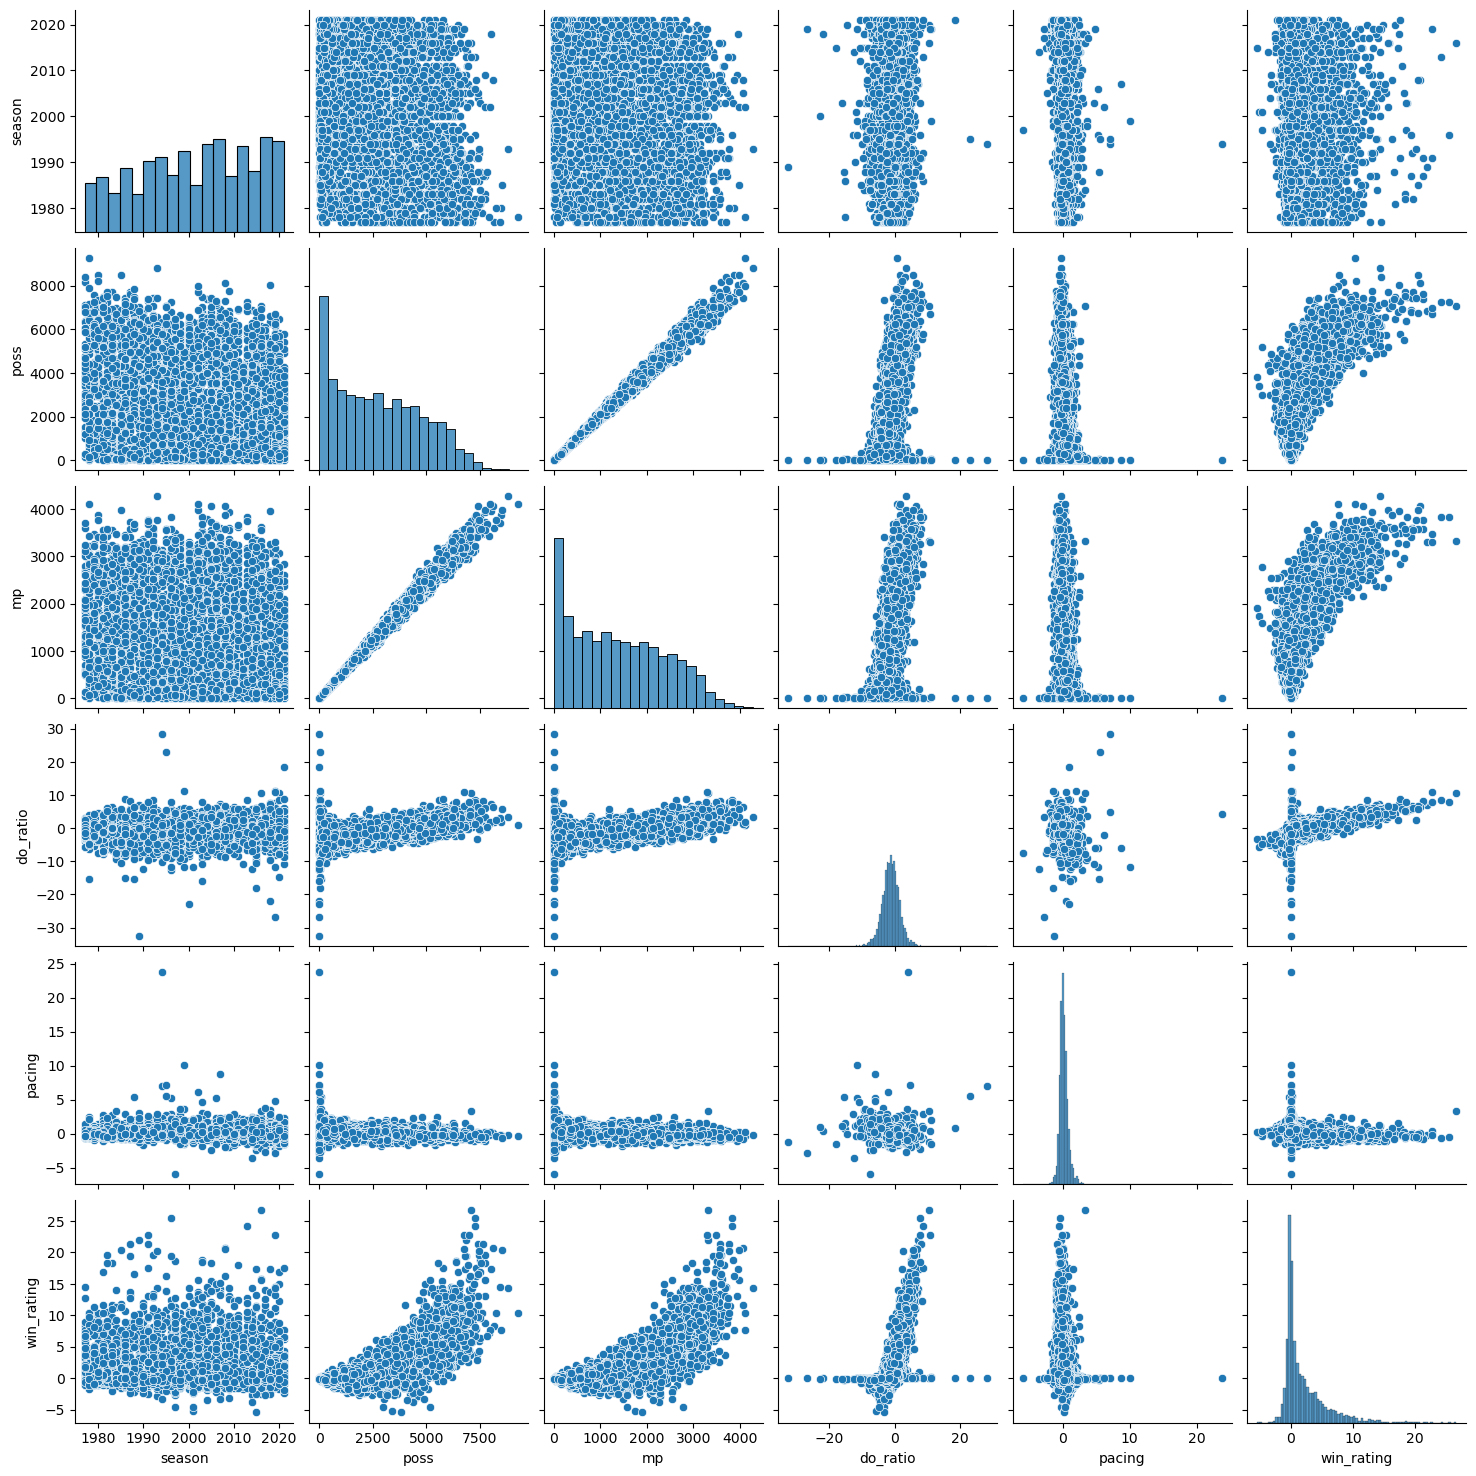

In [52]:
sns.pairplot(df)

In [3]:
#your code here
df = pd.read_csv("NBA.csv")

In [8]:
df.tail()

,season,poss,mp,do_ratio,pacing,win_rating
3995,1986,1224,565,-1.761425,-0.011698,0.082828
3996,1994,3564,1785,0.907199,-0.125856,3.542416
3997,1998,706,378,0.848178,0.694183,0.787185
3998,2003,289,156,-6.298906,0.205844,-0.312601
3999,2000,5733,2912,1.370995,-0.153927,5.380485


**Özellikleri ve hedefi** görüyor musunuz?

> **Your answer here (Double Click)**



## Basit modelleme


### X ve y'yi tanımlayalım




Öncelikle özelliklerimizi (X) ve hedefimizi (y) tanımlamamız gerekiyor.




Basit bir örnekle başlayalım - `X`, bir oyuncunun oynadığı **dakika sayısı** olsun.


`y`'nin ne olması gerektiğini, ulaşmaya çalıştığımız hedeften anlayabilirsiniz!

In [19]:
#your code here
X = df[["mp"]]
y = df[["win_rating"]]



### Eğitim testi bölümü




Makine öğreniminin bir diğer önemli adımı da **eğitim, test ve bölümleme**dir. \
Bu, özellikle veri sızıntısını önlemek için önemlidir.


Sklearn `train_test_split` işlevini kullanarak **4 değişken** `X_train`, `X_test`, `y_train`, `y_test` oluşturun. \
Sözdizimi konusunda emin değilseniz derslere göz atın.








- Nihai sonuçlarınızı arkadaşınızın sonuçlarıyla karşılaştırmak için `random_state=0` kullanın.

In [20]:
#your code here
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0
)


### Özellikleri ölçeklendirme






Sayısal özelliğimizi ölçeklendirmemiz gerekiyor.


**Sklearn** kütüphanesinden istediğiniz bir ölçekleyiciyi içe aktarın ve örneklendirin. Ardından:


1. `X_train`'i uyarlayın ve dönüştürün ve sonuçları `X_train_scaled` değişkenine yükleyin
2. `X_test`'i dönüştürün ve sonuçları `X_test_scaled` değişkenine yükleyin




⚠️ ÖNEMLİ! Test veri kümesini ASLA fit etme.

In [23]:
#your code here
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Modelleme




İşte heyecan verici kısım geliyor!




**Doğrusal Regresyon**, Makine Öğreniminde temel regresyon modelidir!


Şu an için, nasıl çalıştığının ayrıntılarını anlamanıza gerek yok, sadece regresyon görevlerini çok kolay bir şekilde yapabildiğini bilmeniz yeterli!


Eğitim verilerine bir **LinearRegression** modeli içe aktarın, örneklendirin ve uyarlayın!

In [26]:
#your code here
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
model = LinearRegression()
model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False



### Puanlama


Modelimizin performansını değerlendirelim. \
Uyarlanmış modelinizi **test veri kümesinde** puanlayın ve sonucu `single_score` adlı bir değişkende saklayın.






Yaklaşık %54'lük bir puan almalısınız.

In [28]:
#your code here
single_score = model.score(X_test,y_test)
print(f"{single_score}: Score")

0.5509456884683098: Score



Puanı nasıl yorumlayabiliriz?


Şimdilik, büyük olan daha iyidir (ölçek 1'e kadar çıkar). Doğrusal regresyonları ayrıntılı olarak incelediğimizde, bunu nasıl anlamlandırmamız gerektiğini daha derinlemesine anlayacağız.

## Daha eksiksiz bir özellik seti


Şimdi, ilgili tüm özellikler üzerinde **Doğrusal Regresyon**'u deneme zamanı.


Bu sefer `poss`, `mp`, `do_ratio` ve `pacing` özelliklerini kullanarak yeni `X` ve `y` değişkenleri oluşturun.

In [29]:
#your code here
X = df[["poss","mp","do_ratio","pacing"]]
y=df[["win_rating"]]

### Tren testi bölümü




Daha önce yaptığınız gibi `X` ve `y`'yi bölün. \
Sonuçlarınızı arkadaşınızın sonuçlarıyla karşılaştırmak için `random_state=0` ayarını yapmayı unutmayın.

In [30]:
#your code here
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

### Ölçeklendirme


Şimdi, daha önce yaptığımız gibi verileri ölçeklendirme zamanı!

In [33]:
#your code here
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Yeni bir model


Yeni bir dizi özelliğe sahip olduğumuz için, yeni bir model eğitmemiz gerekiyor!


Yeni özelliklerinizle ikinci bir model oluşturun ve eğitin.

In [40]:
#your code here
from sklearn.linear_model import LinearRegression
model_2 = LinearRegression()
model_2.fit(X_train_scaled,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Yeni uyarlanmış modelinizi puanlayın ve sonuçları `multiple_score` adlı bir değişkende saklayın.

In [45]:
#your code here
multiple_score = model_2.score(X_test_scaled, y_test)
print(f"Multiple Score: {multiple_score}")

Multiple Score: 0.6338089274793226


`single_score` ve `multiple_score` değerlerini karşılaştırın.

In [46]:
print(f"SİNGLE Score: {single_score}")
print(f"Multiple Score: {multiple_score}")

SİNGLE Score: 0.5509456884683098
Multiple Score: 0.6338089274793226


> **Tek bir özellik yerine birçok özellik üzerinde bir model eğittiğimizde, puanda önemli bir artış gözlemleyebiliriz.**


## Yeni bir oyuncu geldi!


İşte istatistikleri:


- poss: 4902
- mp: 1845
- do_ratio: 1.011
- pacing: 0.381


Bu yeni oyuncu için tek satırlık bir DataFrame oluşturun!

In [48]:
#your code here
import pandas as pd
new_player = pd.DataFrame([{
    'poss':4902,
    'mp':1845,
    'do_ratio':1.011,
    'pacing':0.381
    
}])


Bu yeni oyuncunun galibiyet oranını tahmin edin!

In [49]:
#your code here

prediction = model_2.predict(new_player)
print("Tahmin edilen win_rating (ölçeklendirilmemiş):", prediction)


Tahmin edilen win_rating (ölçeklendirilmemiş): [[1921.28324122]]


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


## Neler oluyor?


Bu astronomik bir kazanma oranı! Bir şeyi unutmadık mı?


Unuttuk... Neyi unuttuğumuzu bulabilir ve sorunu çözebilir misin? \
Bunu yaptıktan sonra, tahminlere devam edebilirsin!

In [51]:
#your code here
new_player_scaler = scaler.transform(new_player)
correct_prediction = model_2.predict(new_player_scaler)
print("Doğru win_rating tahmini:", correct_prediction)

Doğru win_rating tahmini: [[3.46906345]]


**İlk regresyon modelinizi eğittiğiniz için tebrikler!** 🎉